# Análisis paso a paso: inversión del ruteo fluvial, resolución y diseño de la red de aforos

**Autor:** Néstor O. Vásquez C. · **Repositorio:** `nvasquezc/inversion-ruteo-fluvial-co`

Este cuaderno explica **qué se hizo y por qué**, en el orden en que se construyó. Cada paso tiene tres partes:

1. **Idea**: qué problema resuelve el paso.
2. **Código**: llama al paquete `ruteo_inverso`, cuyo código está en `src/`.
3. **Qué observar**: cómo leer el resultado y qué conclusión se puede sacar (y cuál no).

**Pregunta de investigación.** Con las estaciones de aforo que existen, ¿qué parte de la red de ríos podemos realmente conocer? ¿Dónde convendría instalar la próxima estación?

**Analogía con la inversión geofísica.** En gravimetría o MT se tienen datos en superficie, un operador directo y un modelo del subsuelo. Aquí se tienen caudales en unas pocas estaciones, un modelo de ruteo y un parámetro físico por tramo de río (la rugosidad de Manning, *n*).

| Geofísica | Este proyecto |
|---|---|
| Modelo *m* (densidad, resistividad) | log *n* por tramo |
| Operador directo *G(m)* | Ruteo Muskingum–Cunge |
| Datos *d* (anomalía, impedancia) | Caudal medio diario en estaciones |
| Geometría de adquisición | Ubicación de las estaciones |

> Todo lo que sigue usa **datos sintéticos**, donde conocemos la verdad. Así podemos medir si el método funciona antes de usar datos reales de IDEAM.

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import torch
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)

from ruteo_inverso import *
from ruteo_inverso.graficos import estilo, dibujar_red, SERIE, TEXTO_2
estilo()
torch.set_printoptions(precision=4)
print("torch", torch.__version__)

torch 2.14.1+cpu


## Paso 1 — La red fluvial como grafo dirigido

**Idea.** Un río es un **árbol dirigido**: cada tramo drena hacia un único tramo aguas abajo, hasta llegar a la salida. Se usa una convención de **orden topológico**: todo tramo aguas arriba tiene un índice menor que el tramo al que drena.

**Por qué importa.** Con ese orden, la matriz de adyacencia $A$ (con $A_{ji}=1$ si el tramo $i$ drena en $j$) es **triangular inferior estricta**. Así, el caudal de toda la red en cada instante se calcula con una sola sustitución hacia adelante, sin iterar.

Cada tramo tiene longitud $L$, pendiente $S_0$, ancho $B$ y área local de aporte. Ancho y pendiente siguen leyes de potencia del área de drenaje (geometría hidráulica de Leopold y Maddock). Los coeficientes son **ilustrativos, no calibrados para Colombia**.

In [2]:
red = red_sintetica(n_tramos=60, semilla=0)
A_dren = red.area_drenaje_km2()
salida = int(np.where(red.aguas_abajo < 0)[0][0])

print(f"tramos: {red.n}   salida: tramo {salida}   área total: {A_dren[salida]:,.0f} km²")
print(f"longitud de tramos: {red.longitud_m.min()/1e3:.1f}–{red.longitud_m.max()/1e3:.1f} km")
print(f"pendiente: {red.pendiente.min():.1e}–{red.pendiente.max():.1e} m/m")
A = red.adyacencia()
print("¿A es triangular inferior estricta?", bool(torch.all(torch.triu(A) == 0)))
print("conexiones:", int(A.sum()), "(= n − 1, como corresponde a un árbol)")

tramos: 60   salida: tramo 59   área total: 18,706 km²
longitud de tramos: 7.9–32.5 km
pendiente: 3.1e-04–3.9e-03 m/m


¿A es triangular inferior estricta? True
conexiones: 59 (= n − 1, como corresponde a un árbol)


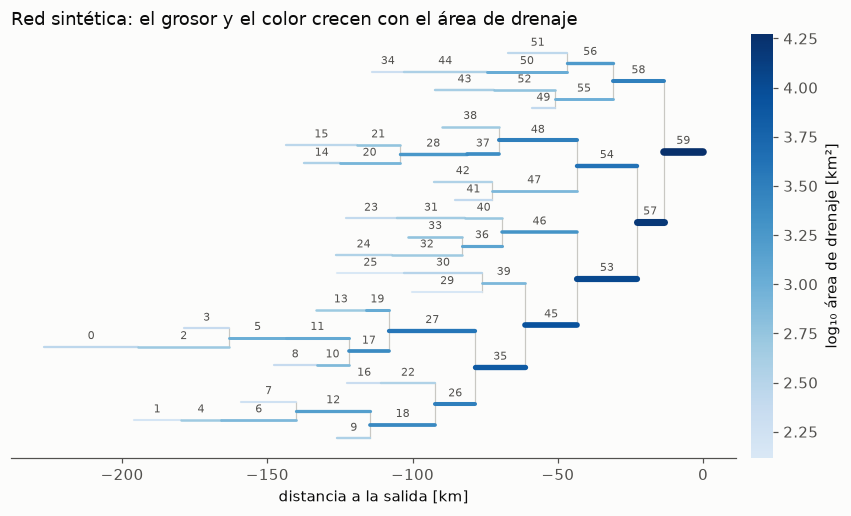

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
dibujar_red(red, ax, valores=np.log10(A_dren), etiqueta_color="log₁₀ área de drenaje [km²]",
            anotar=range(red.n))
ax.set_title("Red sintética: el grosor y el color crecen con el área de drenaje", loc="left")
plt.show()

**Qué observar.** La salida está en $x=0$ y los tributarios se extienden aguas arriba (hacia $x$ negativo). Los tramos de cabecera son delgados (poca área). El cauce principal se engrosa a medida que recibe afluentes.

## Paso 2 — El forzamiento: aporte lateral de cada subcuenca

**Idea.** Cada tramo recibe agua de su subcuenca local. En el sintético se generan **tormentas** con cobertura espacial parcial. Cada subcuenca convierte la lluvia en escorrentía con un **embalse lineal**, al que se suma un caudal base.

**Por qué importa.** Si toda la cuenca recibiera la misma lluvia al mismo tiempo, sería imposible distinguir un tramo lento de otro rápido. La **variabilidad espacio‑temporal** del aporte es la que, en principio, hace identificables los parámetros.

En datos reales, este aporte vendrá de un modelo lluvia‑escorrentía (por ejemplo, un LSTM) forzado con CHIRPS y MSWX, como en CAMELS‑COL.

aporte lateral q: (960, 60) (horas × tramos), m³/s


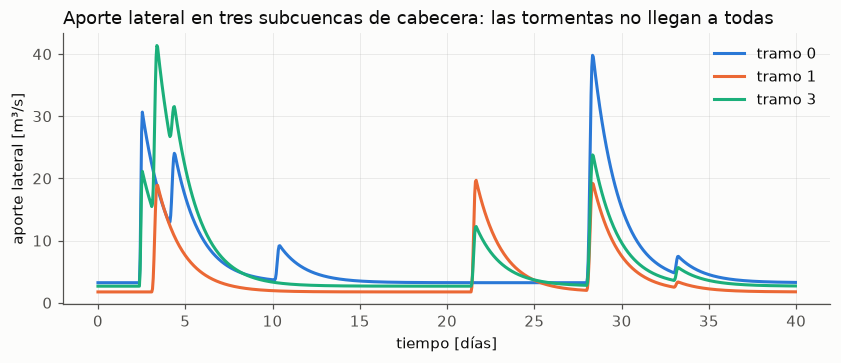

In [4]:
PASOS_DIA, DIAS = 24, 40
q = aporte_lateral_sintetico(red, dias=DIAS, pasos_por_dia=PASOS_DIA, semilla=0)
print("aporte lateral q:", tuple(q.shape), "(horas × tramos), m³/s")

t_dias = np.arange(q.shape[0]) / PASOS_DIA
cabeceras = [i for i in range(red.n) if i not in set(red.aguas_abajo)][:3]
fig, ax = plt.subplots(figsize=(9, 3.2))
for k, i in enumerate(cabeceras):
    ax.plot(t_dias, q[:, i], label=f"tramo {i}", color=SERIE[k])
ax.set_xlabel("tiempo [días]"); ax.set_ylabel("aporte lateral [m³/s]")
ax.set_title("Aporte lateral en tres subcuencas de cabecera: las tormentas no llegan a todas", loc="left")
ax.legend(frameon=False); plt.show()

## Paso 3 — El operador directo: ruteo Muskingum–Cunge diferenciable

**Idea.** El agua que entra a un tramo no sale de inmediato. Se **retrasa** y se **atenúa** según la rapidez de la onda en el cauce. Muskingum describe cada tramo con dos números, $K$ (tiempo de tránsito) y $X$ (peso de la entrada en el almacenamiento):

$$S = K\,[X\,I + (1-X)\,O], \qquad O_t = c_0 I_t + c_1 I_{t-1} + c_2 O_{t-1}$$

$$c_0=\frac{\Delta t-2KX}{D},\quad c_1=\frac{\Delta t+2KX}{D},\quad c_2=\frac{2K(1-X)-\Delta t}{D},\quad D=2K(1-X)+\Delta t$$

**Cunge** conecta $K$ y $X$ con la física del cauce. Para un canal rectangular ancho, la ecuación de Manning da la profundidad, la velocidad y la celeridad de la onda:

$$Q=\tfrac{1}{n}B\,h^{5/3}S_0^{1/2}\;\Rightarrow\; c=\tfrac{5}{3}v,\qquad K=\frac{L}{c},\qquad X=\tfrac12\Big(1-\frac{Q}{B S_0 c L}\Big)$$

La rugosidad $n$ es el **parámetro desconocido**. Un cauce rugoso (*n* grande) es más lento: $K$ crece y el pico llega más tarde y más atenuado.

**Diferenciable** quiere decir que todo está escrito en PyTorch, así que se obtiene $\partial\,\text{caudal}/\partial n$ automáticamente. Es lo mismo que el operador de impedancia diferenciable del MT‑1D del curso.

**Simplificación declarada.** La celeridad se evalúa en un **caudal de referencia fijo** (el medio de cada tramo). Por eso los coeficientes no cambian en el tiempo y el ruteo es *lineal*. La versión no lineal es el experimento E02.

In [5]:
q_ref = caudal_referencia(red, q)
modelo = MuskingumCunge(red, q_ref, dt_s=3600.0)
log_n_verdadero = rugosidad_verdadera(red, semilla=0)

co = modelo.coeficientes(log_n_verdadero)
print("n verdadero:  %.3f – %.3f" % (log_n_verdadero.exp().min(), log_n_verdadero.exp().max()))
print("K (horas):    %.1f – %.1f" % (co.K.min()/3600, co.K.max()/3600))
print("X:            %.2f – %.2f" % (co.X.min(), co.X.max()))
print("c0+c1+c2 = 1 en todos los tramos:", bool(torch.allclose(co.c0+co.c1+co.c2, torch.ones(red.n, dtype=torch.float64))))
print("diagnóstico de estabilidad:", modelo.diagnostico_courant(log_n_verdadero))

n verdadero:  0.020 – 0.064
K (horas):    1.2 – 10.5
X:            0.05 – 0.38


c0+c1+c2 = 1 en todos los tramos: True
diagnóstico de estabilidad: {'frac_c2_negativo': 0.0, 'K_min_h': 1.1833391514468283, 'K_max_h': 10.53962813100673}


**Cómo se resuelve un paso de tiempo para toda la red.** La entrada a cada tramo es la salida de sus afluentes más el aporte lateral: $I_t = A\,O_t + q_t$. Al sustituirla en Muskingum queda un sistema lineal triangular:

$$(\mathbb{I} - \mathrm{diag}(c_0)A)\,O_t = c_0\,q_t + c_1 I_{t-1} + c_2 O_{t-1}$$

Como la matriz es triangular inferior con diagonal unitaria, se invierte una sola vez y se reutiliza en cada paso.

volumen del pulso en cada punto [hm³]: [2.16, 2.16, 2.16] (debe ser el mismo: 2.16)


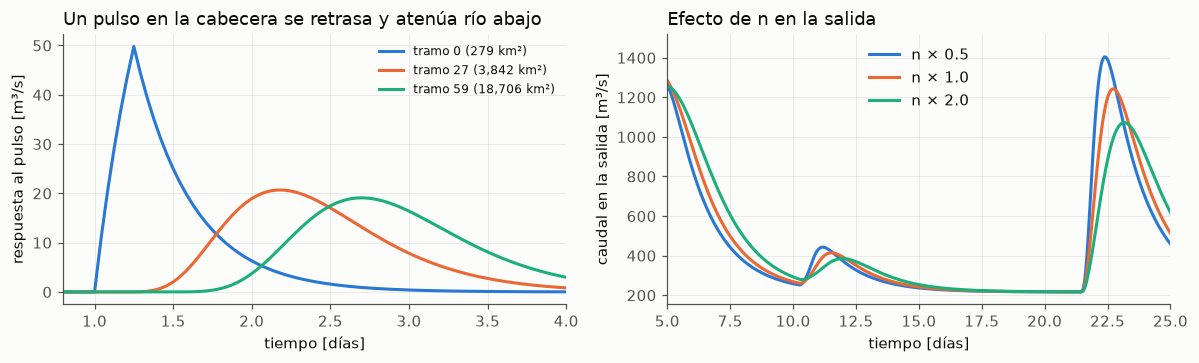

In [6]:
O, I, S = modelo.rutear(log_n_verdadero, q, devolver_estado=True)

# camino desde una cabecera hasta la salida
camino = [cabeceras[0]]
while red.aguas_abajo[camino[-1]] >= 0:
    camino.append(int(red.aguas_abajo[camino[-1]]))
mostrar = [camino[0], camino[len(camino)//2], camino[-1]]

# Experimento de pulso: caudal base constante + un pulso de 6 h solo en la cabecera
q_pulso = q[:1].repeat(10 * PASOS_DIA, 1).clone()
q_pulso[PASOS_DIA:PASOS_DIA + 6, camino[0]] += 100.0
O_pulso = modelo.rutear(log_n_verdadero, q_pulso)
exceso = O_pulso - O_pulso[0]          # respuesta al pulso (se resta el caudal base)
t10 = np.arange(q_pulso.shape[0]) / PASOS_DIA

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for k, i in enumerate(mostrar):
    axs[0].plot(t10, exceso[:, i], label=f"tramo {i} ({A_dren[i]:,.0f} km²)", color=SERIE[k])
axs[0].set_xlim(0.8, 4); axs[0].set_xlabel("tiempo [días]"); axs[0].set_ylabel("respuesta al pulso [m³/s]")
axs[0].set_title("Un pulso en la cabecera se retrasa y atenúa río abajo", loc="left")
axs[0].legend(frameon=False, fontsize=8)
print("volumen del pulso en cada punto [hm³]:", [round(float(exceso[:, i].sum() * 3600 / 1e6), 3) for i in mostrar],
      "(debe ser el mismo: 2.16)")

for k, factor in enumerate([0.5, 1.0, 2.0]):
    Of = modelo.rutear(log_n_verdadero + np.log(factor), q)
    axs[1].plot(t_dias, Of[:, salida], label=f"n × {factor}", color=SERIE[k])
axs[1].set_xlim(5, 25); axs[1].set_xlabel("tiempo [días]"); axs[1].set_ylabel("caudal en la salida [m³/s]")
axs[1].set_title("Efecto de n en la salida", loc="left")
axs[1].legend(frameon=False); plt.tight_layout(); plt.show()

**Qué observar.** A la izquierda, el mismo volumen de agua (el área bajo cada curva es igual) llega cada vez más tarde y con un pico más bajo y ancho. Eso es el ruteo. En la gráfica derecha, duplicar o reducir a la mitad la rugosidad **en todos los tramos** solo cambia un poco el hidrograma de salida: el pico se adelanta o se atrasa unas horas. Esta es la primera pista del hallazgo central: **el caudal es poco sensible a *n***, sobre todo cuando se observa como promedio diario.

## Paso 4 — Verificar que la masa se conserva (restricción dura)

**Idea.** En una red neuronal "informada por la física" típica (PINN), la física entra como una **penalización** en la pérdida, que se cumple solo aproximadamente. Aquí la conservación de masa es una **propiedad de la arquitectura**. Como $c_0+c_1+c_2=1$, el esquema cumple *exactamente* la continuidad discreta:

$$\Delta t\sum_t \tfrac12\big[(I_t+I_{t+1})-(O_t+O_{t+1})\big] = S_T - S_0$$

Se verifica en cada tramo y en toda la red: lo que entra lateralmente = lo que sale por la salida + lo que quedó almacenado.

In [7]:
dt = modelo.dt
lhs = dt * 0.5 * ((I[:-1] + I[1:]) - (O[:-1] + O[1:])).sum(0)
rhs = S[-1] - S[0]
vol = dt * I.sum(0)
print(f"error relativo máximo por tramo: {float(((lhs - rhs).abs() / vol).max()):.2e}")

entra = dt * 0.5 * (q[:-1] + q[1:]).sum()
sale  = dt * 0.5 * (O[:-1, salida] + O[1:, salida]).sum()
dS    = (S[-1] - S[0]).sum()
print(f"red completa: entra {entra/1e9:.4f} km³, sale {sale/1e9:.4f} km³, ΔS {dS/1e9:.4f} km³")
print(f"error de cierre: {float(abs(entra - sale - dS) / entra):.2e}")

error relativo máximo por tramo: 4.99e-16
red completa: entra 1.5679 km³, sale 1.5677 km³, ΔS 0.0002 km³
error de cierre: 1.20e-17


**Qué observar.** El error está en el orden de $10^{-15}$–$10^{-12}$, es decir, precisión de máquina. Ningún valor del parámetro $n$ puede "crear" o "destruir" agua. Esa es la diferencia con el cuaderno exploratorio original (PIGNN de Chapinero), donde la física era una penalización y había que subir mucho $\lambda$ para que tuviera efecto.

## Paso 5 — Observaciones sintéticas: pocas estaciones y datos diarios

**Idea.** Se imita la situación colombiana:

- **Pocas estaciones** (3): la salida y las dos subcuencas de mayor área, porque así suele ubicarse una red real: en ríos grandes y accesibles.
- **Caudal medio diario**, que es lo que publican IDEAM y CAMELS‑COL, aunque el ruteo se resuelva cada hora.
- **Error de observación** del 5 % más un piso de 0,5 m³/s, como incertidumbre de la curva de gasto.

Luego se olvida la verdad y se intenta recuperarla solo a partir de estos datos.

estaciones: [59, 57, 53]  áreas: [18706 15397 10905] km²
datos: (40, 3) (días × estaciones) → 111 datos usados (sin calentamiento)


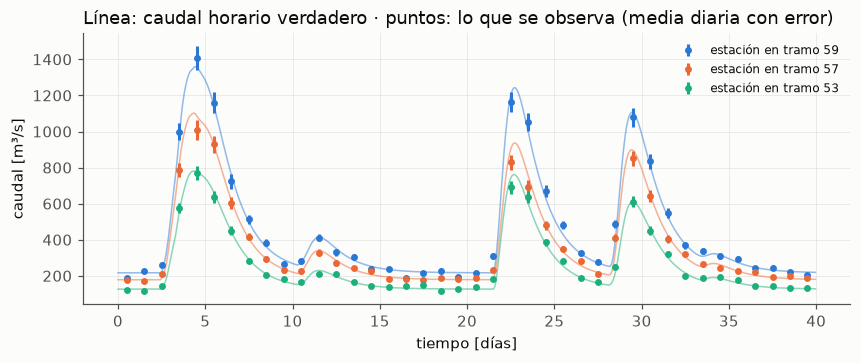

In [8]:
estaciones = [salida] + [int(i) for i in np.argsort(-A_dren) if i != salida][:2]
d_obs, sigma = sintetizar_observaciones(modelo, log_n_verdadero, q, estaciones, PASOS_DIA,
                                        ruido_rel=0.05, piso_m3s=0.5, semilla=0)
problema = ProblemaInverso(modelo, q, estaciones, PASOS_DIA, d_obs, sigma, dias_calentamiento=3)
print("estaciones:", estaciones, " áreas:", np.round(A_dren[estaciones]).astype(int), "km²")
print("datos:", tuple(d_obs.shape), "(días × estaciones) →", problema.n_datos, "datos usados (sin calentamiento)")

fig, ax = plt.subplots(figsize=(9, 3.2))
dias = np.arange(d_obs.shape[0]) + 0.5
for k, e in enumerate(estaciones):
    ax.plot(t_dias, O[:, e], color=SERIE[k], lw=1, alpha=0.5)
    ax.errorbar(dias, d_obs[:, k], yerr=sigma[:, k], fmt="o", ms=3.5, color=SERIE[k], label=f"estación en tramo {e}")
ax.set_xlabel("tiempo [días]"); ax.set_ylabel("caudal [m³/s]")
ax.set_title("Línea: caudal horario verdadero · puntos: lo que se observa (media diaria con error)", loc="left")
ax.legend(frameon=False, fontsize=8); plt.show()

## Paso 6 — Sensibilidad: ¿cuánto "ven" los datos a la rugosidad?

**Idea.** Antes de invertir hay que preguntar si los datos contienen información sobre el parámetro. Se usan dos herramientas:

1. **Barrido de un factor global:** se multiplica todo *n* por un factor y se mide el desajuste $\phi_d=\sum (d-d_{obs})^2/\sigma^2$. Si la curva es plana, los datos no distinguen.
2. **Jacobiano** $J=\partial d/\partial \log n$, calculado con diferenciación automática (`torch.func.jacfwd`). Indica cuánto cambia el caudal de cada estación ante un cambio en cada tramo.

Por referencia: si el modelo es correcto, $\phi_d \approx N$ (el número de datos), con desviación $\sqrt{2N}$.

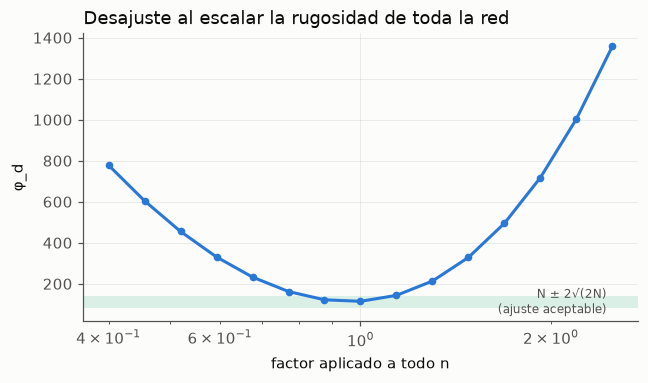

In [9]:
factores = np.exp(np.linspace(np.log(0.4), np.log(2.5), 15))
phis = [float(problema.phi_d(log_n_verdadero + np.log(f))) for f in factores]
N = problema.n_datos

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(factores, phis, marker="o", ms=4, color=SERIE[0])
ax.axhspan(N - 2*np.sqrt(2*N), N + 2*np.sqrt(2*N), color=SERIE[2], alpha=0.15, lw=0)
ax.text(2.45, N, "N ± 2√(2N)\n(ajuste aceptable)", ha="right", va="center", fontsize=8, color=TEXTO_2)
ax.set_xscale("log"); ax.set_xlabel("factor aplicado a todo n"); ax.set_ylabel("φ_d")
ax.set_title("Desajuste al escalar la rugosidad de toda la red", loc="left"); plt.show()

**Qué observar.** El escalamiento **global** sí se detecta: con un factor de 0,5 o 2, $\phi_d$ sale de la banda aceptable. Pero la curva es poco profunda cerca de 1. Si apenas se distingue un cambio uniforme del ±25 %, será todavía más difícil resolver un campo con **60 valores distintos**. El Jacobiano muestra dónde está la información.

Jacobiano: (37, 60, 60)


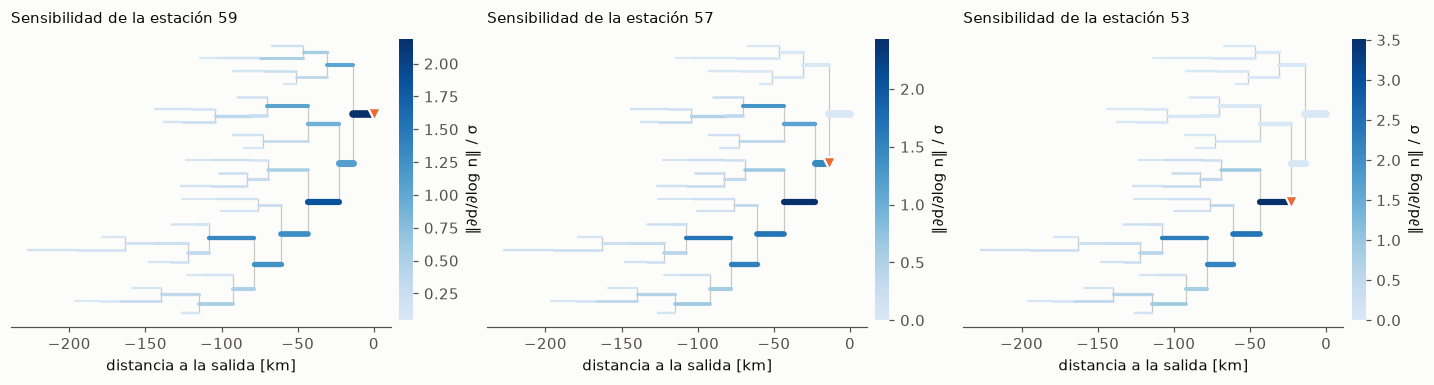

sensibilidad a tramos que NO drenan a la estación 57 = 0.0


In [10]:
J = jacobiano_diario(modelo, log_n_verdadero, q, PASOS_DIA, dias_calentamiento=3)  # (días, tramos_obs, parámetros)
print("Jacobiano:", tuple(J.shape))

# sensibilidad total de cada estación a cada tramo (norma en el tiempo, normalizada por σ)
Qd = promedio_diario(O, PASOS_DIA)[3:]
sig_todos = 0.05 * Qd + 0.5
sens = ((J / sig_todos[..., None]) ** 2).sum(0).sqrt()   # (tramo observado, parámetro)

fig, axs = plt.subplots(1, len(estaciones), figsize=(13, 3.6))
for k, e in enumerate(estaciones):
    dibujar_red(red, axs[k], valores=sens[e].numpy(), estaciones=[e], cmap="Blues",
                etiqueta_color="‖∂d/∂log n‖ / σ")
    axs[k].set_title(f"Sensibilidad de la estación {e}", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

# causalidad: una estación no puede ser sensible a tramos que no drenan hacia ella
fuera = ~torch.as_tensor(red.aguas_arriba_de(estaciones[1]))
print("sensibilidad a tramos que NO drenan a la estación", estaciones[1], "=", float(J[:, estaciones[1], fuera].abs().max()))

**Qué observar.**
- Cada estación solo es sensible a los tramos que drenan hacia ella (causalidad física, verificada con sensibilidad exactamente 0 fuera de su cuenca).
- La sensibilidad se concentra en los **tramos largos del cauce principal**. En las cabeceras pequeñas es casi nula: sus tiempos de tránsito son de pocas horas y desaparecen al promediar a escala diaria.

## Paso 7 — Inversión de Tikhonov (estilo SimPEG)

**Idea.** Se busca el campo $m=\log n$ que minimiza

$$\phi(m) = \underbrace{\|W_d(P\,G(m)-d_{obs})\|^2}_{\phi_d\text{: ajuste a datos}} + \beta\,\underbrace{\big(\alpha_s\|m-m_{ref}\|^2 + \alpha_x\|D(m-m_{ref})\|^2\big)}_{\phi_m\text{: regularización}}$$

- $m_{ref}=\log 0.035$: un valor típico de río natural (Chow, 1959), igual en toda la red. Es lo que diría un hidrólogo sin datos.
- $D$: diferencias entre tramos conectados, la "suavidad" a lo largo del río.
- $\beta$ se elige **como en SimPEG**:
  - $\beta_0$ se estima con una dirección aleatoria, para equilibrar las curvaturas de los dos términos (`BetaEstimate`).
  - Luego $\beta$ se divide entre 4 por etapa (`BetaSchedule`).
  - El proceso se detiene cuando $\phi_d \le N + 2\sqrt{2N}$ (`TargetMisfit`) o cuando bajar $\beta$ ya no mejora el ajuste.
- La tolerancia $2\sqrt{2N}$ es importante. Exigir $\phi_d\le N$ exacto lleva a sobreajustar el ruido. Ocurrió en una primera versión: en 2 de 12 redes la inversión llevó *n* a los límites.

In [11]:
m_ref = torch.full((red.n,), float(np.log(0.035)), dtype=torch.float64)
D = red.laplaciano()
res_tik = invertir_tikhonov(problema, m_ref, D, alpha_s=1.0, alpha_x=1.0)
for h in res_tik.historial:
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in h.items()})

rmse = lambda m: float(((m - log_n_verdadero) ** 2).mean().sqrt())
print(f"\nRMSE log n — referencia sin datos: {rmse(m_ref):.3f}   invertido: {rmse(res_tik.log_n):.3f}")

{'etapa': 0, 'beta': 9.283, 'phi_d': 116.03, 'phi_m': 1.009, 'objetivo': 140.799}

RMSE log n — referencia sin datos: 0.303   invertido: 0.291


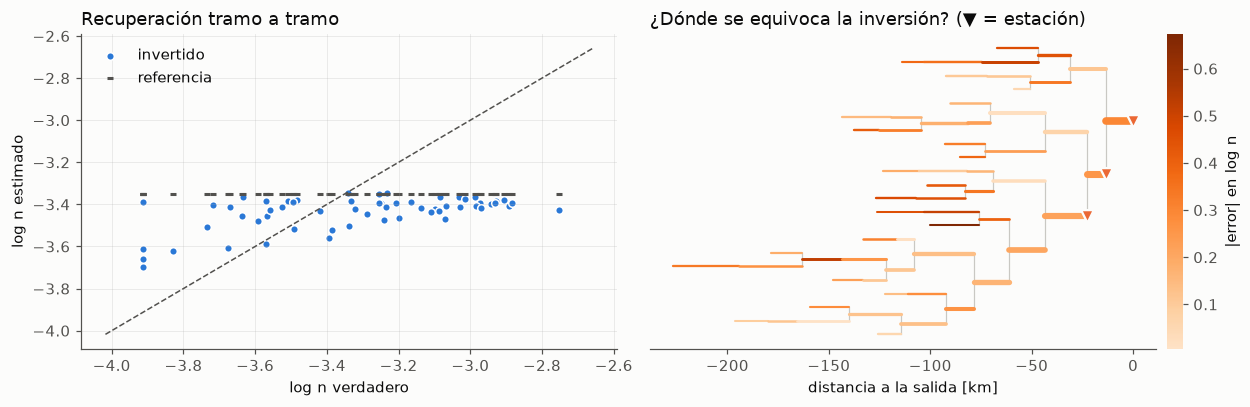

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.8))
lim = (np.log(0.018), np.log(0.07))
axs[0].scatter(log_n_verdadero, res_tik.log_n, s=25, color=SERIE[0], edgecolor="white", label="invertido")
axs[0].scatter(log_n_verdadero, m_ref, s=12, color=TEXTO_2, marker="_", label="referencia")
axs[0].plot(lim, lim, color=TEXTO_2, lw=1, ls="--")
axs[0].set_xlabel("log n verdadero"); axs[0].set_ylabel("log n estimado")
axs[0].set_title("Recuperación tramo a tramo", loc="left"); axs[0].legend(frameon=False)
dibujar_red(red, axs[1], valores=(res_tik.log_n - log_n_verdadero).abs().numpy(), estaciones=estaciones,
            cmap="Oranges", etiqueta_color="|error| en log n")
axs[1].set_title("¿Dónde se equivoca la inversión? (▼ = estación)", loc="left")
plt.tight_layout(); plt.show()

**Qué observar.** La inversión mejora respecto a la referencia, pero **poco**. Muchos puntos quedan en una franja horizontal cerca de la referencia: en esos tramos los datos no dicen nada y la regularización decide. El paso siguiente cuantifica esto tramo por tramo.

## Paso 8 — Matriz de resolución: ¿qué viene de los datos y qué de los supuestos?

**Idea (Menke; Aster et al.).** Al linealizar alrededor de la solución:

$$H = J^\top W_d^2 J + \beta\,W_m^\top W_m, \qquad R = H^{-1}J^\top W_d^2 J, \qquad C_{post}\approx H^{-1}$$

- $\mathrm{diag}(R)_i \approx 1$: el tramo $i$ está **resuelto por los datos**.
- $\mathrm{diag}(R)_i \approx 0$: su valor lo impone la **regularización** (no identificable).
- $\sqrt{\mathrm{diag}(C_{post})}$: incertidumbre aproximada de cada $\log n_i$.

Es el equivalente de la "profundidad de investigación" en gravimetría o MT: indica hasta dónde llega el poder de los datos.

**Advertencia.** Es un análisis **local y lineal**. Para conclusiones globales se necesita muestreo (E03 del protocolo).

diag(R): mediana 0.006, máx 0.279
tramos con diag(R) > 0.1: 6 de 60
suma de diag(R) (≈ número de parámetros efectivamente resueltos): 1.7


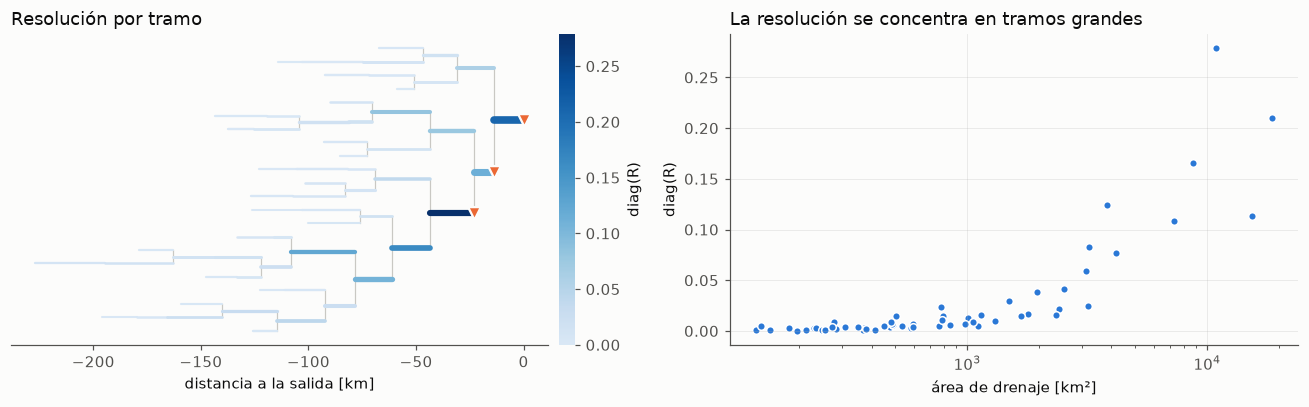

In [13]:
Wm2 = matriz_regularizacion(red.n, D, 1.0, 1.0)
J_hat = jacobiano_diario(modelo, res_tik.log_n, q, PASOS_DIA, 3)
with torch.no_grad():
    Qd_hat = promedio_diario(modelo.rutear(res_tik.log_n, q), PASOS_DIA)[3:]
sig_hat = 0.05 * Qd_hat.abs() + 0.5
reso = resolucion(J_hat[:, estaciones], sig_hat[:, estaciones], Wm2, res_tik.beta)

dR = reso.diag_R.numpy()
print(f"diag(R): mediana {np.median(dR):.3f}, máx {dR.max():.3f}")
print(f"tramos con diag(R) > 0.1: {(dR > 0.1).sum()} de {red.n}")
print(f"suma de diag(R) (≈ número de parámetros efectivamente resueltos): {dR.sum():.1f}")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
dibujar_red(red, axs[0], valores=dR, estaciones=estaciones, cmap="Blues", vmin=0, etiqueta_color="diag(R)")
axs[0].set_title("Resolución por tramo", loc="left")
axs[1].scatter(A_dren, dR, s=25, color=SERIE[0], edgecolor="white")
axs[1].set_xscale("log"); axs[1].set_xlabel("área de drenaje [km²]"); axs[1].set_ylabel("diag(R)")
axs[1].set_title("La resolución se concentra en tramos grandes", loc="left")
plt.tight_layout(); plt.show()

**Qué observar.**
- Con 3 estaciones de datos diarios, toda la red equivale a resolver apenas **unos pocos parámetros efectivos** (la suma de diag(R)), no 60.
- Los tramos resueltos son los grandes y cercanos a las estaciones, lo cual concuerda con que Bindas et al. (2024) solo vieran beneficio en subcuencas mayores a 2000 km².
- **Consecuencia práctica.** Un mapa de *n* aprendido sin este análisis puede parecer detallado, pero en la mayoría de los tramos está mostrando el supuesto, no los datos.

## Paso 9 — Diseño de la red: ¿dónde poner la próxima estación?

**Idea (diseño óptimo de experimentos).** Cada tramo candidato $c$ aportaría una matriz de información $F_c = J_c^\top W_d^2 J_c$. Se elige la estación que maximiza $\log\det(H + F_c)$ (**criterio D**: reduce el volumen de la incertidumbre posterior). Luego se repite de forma **codiciosa** para $k$ estaciones.

**Importante.** El diseño se calcula con el **modelo de referencia** $m_{ref}$, no con la verdad, como ocurriría en la práctica antes de instalar.

Se comparan tres estrategias para agregar 4 estaciones:
- **D‑óptimo** (este método).
- **Mayor área**: la heurística tradicional, aforar los ríos más grandes.
- **Aleatorio**.

Cada estrategia se evalúa **reinvirtiendo** con nuevos datos sintéticos.

In [14]:
K_NUEVAS = 4
J_ref = jacobiano_diario(modelo, m_ref, q, PASOS_DIA, 3)
with torch.no_grad():
    Qd_ref = promedio_diario(modelo.rutear(m_ref, q), PASOS_DIA)[3:]
sig_ref = 0.05 * Qd_ref.abs() + 0.5
F = informacion_por_candidato(J_ref, sig_ref)
H_base = resolucion(J_ref[:, estaciones], sig_ref[:, estaciones], Wm2, res_tik.beta).H

d_optimo, _ = diseno_codicioso(F, H_base, K_NUEVAS, excluir=estaciones, criterio="D")
mayor_area = [int(i) for i in np.argsort(-A_dren) if i not in estaciones][:K_NUEVAS]
rng = np.random.default_rng(0)
aleatorio = list(rng.choice([i for i in range(red.n) if i not in estaciones], K_NUEVAS, replace=False))

def evaluar(extra):
    est = estaciones + [int(e) for e in extra]
    d, s = sintetizar_observaciones(modelo, log_n_verdadero, q, est, PASOS_DIA, 0.05, 0.5, semilla=0)
    r = invertir_tikhonov(ProblemaInverso(modelo, q, est, PASOS_DIA, d, s, 3), m_ref, D, 1.0, 1.0)
    return rmse(r.log_n), r

resultados = {nombre: evaluar(extra) for nombre, extra in
              [("D-óptimo", d_optimo), ("mayor área", mayor_area), ("aleatorio", aleatorio)]}
print("estaciones nuevas  D-óptimo:", d_optimo, " mayor área:", mayor_area, " aleatorio:", [int(a) for a in aleatorio])
print(f"RMSE solo red base: {rmse(res_tik.log_n):.3f}")
for k, (v, _) in resultados.items():
    print(f"RMSE con +4 ({k:>10}): {v:.3f}")

estaciones nuevas  D-óptimo: [11, 50, 55, 46]  mayor área: [45, 35, 54, 27]  aleatorio: [15, 28, 45, 35]
RMSE solo red base: 0.291
RMSE con +4 (  D-óptimo): 0.256
RMSE con +4 (mayor área): 0.292
RMSE con +4 ( aleatorio): 0.291


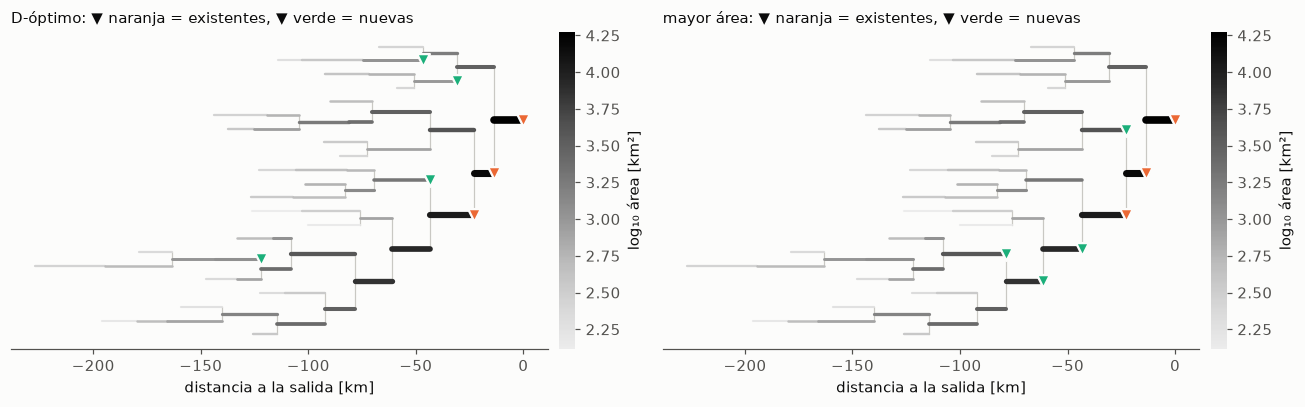

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (nombre, extra) in zip(axs, [("D-óptimo", d_optimo), ("mayor área", mayor_area)]):
    dibujar_red(red, ax, valores=np.log10(A_dren), estaciones=estaciones, estaciones_nuevas=extra,
                cmap="Greys", etiqueta_color="log₁₀ área [km²]")
    ax.set_title(f"{nombre}: ▼ naranja = existentes, ▼ verde = nuevas", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**Qué observar.** La heurística de mayor área coloca las estaciones nuevas **junto a las existentes**, sobre el mismo cauce principal, y por eso aporta información redundante. El diseño D‑óptimo las reparte en **tributarios grandes que aún no se ven**. En esta red concreta la diferencia es pequeña. La conclusión **no se saca de una red**: se saca de 12 en el Paso 11.

## Paso 10 — Inversión neuronal no supervisada (análogo al reto MT‑1D)

**Idea.** En vez de estimar 60 valores sueltos, se entrena una red $f_\theta(\text{atributos del tramo}) \to \log n$ con pendiente, área, ancho y longitud como entradas. Se entrena **sin etiquetas de n**: la pérdida es solo el desajuste de datos *a través del operador directo*, igual que la inversión profunda no supervisada del MT‑1D del curso. Es también la estrategia de Bindas et al. (2024).

**Ventaja.** Sirve para predecir *n* en tramos **sin aforo**, porque solo necesita sus atributos.
**Riesgo.** Si la verdad no depende de los atributos, la red no puede inventar esa información.

φ_d/N inicial 7.01 → final 1.01
RMSE log n — referencia 0.303 | Tikhonov 0.291 | neuronal 0.666


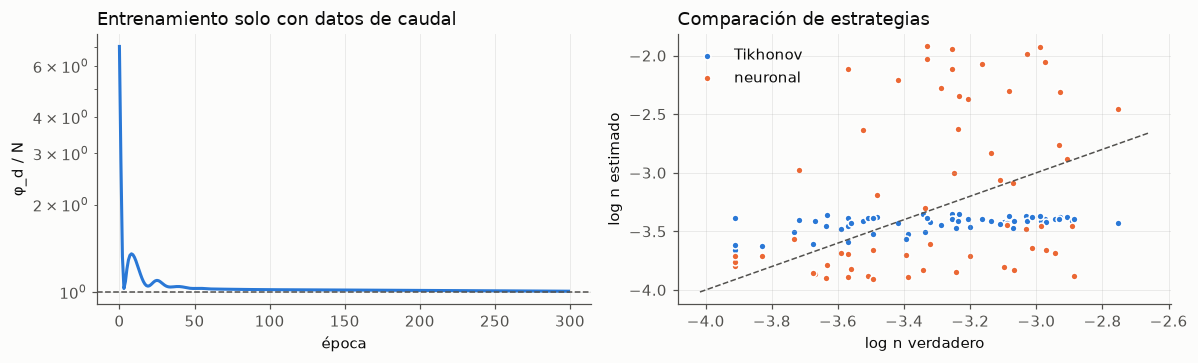

In [16]:
X_attr = torch.as_tensor(red.atributos(), dtype=torch.float64)
f_red, hist = invertir_neuronal(problema, X_attr, epocas=300, lr=1e-2, semilla=0)
with torch.no_grad():
    log_n_nn = f_red(X_attr)
print(f"φ_d/N inicial {hist[0]:.2f} → final {hist[-1]:.2f}")
print(f"RMSE log n — referencia {rmse(m_ref):.3f} | Tikhonov {rmse(res_tik.log_n):.3f} | neuronal {rmse(log_n_nn):.3f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].plot(hist, color=SERIE[0]); axs[0].axhline(1, color=TEXTO_2, ls="--", lw=1)
axs[0].set_yscale("log"); axs[0].set_xlabel("época"); axs[0].set_ylabel("φ_d / N")
axs[0].set_title("Entrenamiento solo con datos de caudal", loc="left")
axs[1].scatter(log_n_verdadero, res_tik.log_n, s=20, color=SERIE[0], label="Tikhonov", edgecolor="white")
axs[1].scatter(log_n_verdadero, log_n_nn, s=20, color=SERIE[1], label="neuronal", edgecolor="white")
axs[1].plot(lim, lim, color=TEXTO_2, ls="--", lw=1)
axs[1].set_xlabel("log n verdadero"); axs[1].set_ylabel("log n estimado"); axs[1].legend(frameon=False)
axs[1].set_title("Comparación de estrategias", loc="left"); plt.tight_layout(); plt.show()

**Qué observar.** La red neuronal ajusta los datos ($\phi_d/N \approx 1$, tan bien como Tikhonov), pero en esta ejecución su error en *n* es **mayor que el de no usar datos**. **Ajustar los datos no garantiza recuperar el parámetro.** Es la no unicidad de la Sesión 01 del curso. Esta red no tiene regularización explícita sobre *n*, así que puede encontrar un campo distinto que explica igual de bien los caudales. Compararla de forma justa con Tikhonov (con parada temprana, ensembles, varias semillas) queda para un experimento posterior. Aquí solo se muestra que el mecanismo funciona.

## Paso 11 — Resultado agregado: experimento E01 (12 redes)

Una sola red puede engañar. El script `experiments/e01_identificabilidad_sintetica.py` repite los pasos 5–9 en **12 redes distintas**, con 5 sorteos aleatorios por red. Aquí se leen sus resultados guardados (`results/e01_resultados.json`). Para regenerarlos se ejecuta `uv run python experiments/e01_identificabilidad_sintetica.py --redes 12 --aleatorios 5` (unos 5 min).

**Hipótesis (definidas antes de mirar los resultados):**
- **H1:** diag(R), calculada sin conocer la verdad, predice el error. Se espera una correlación de Spearman negativa.
- **H2:** el diseño D‑óptimo reduce el error más que la heurística de mayor área y que el azar. Se usa Wilcoxon pareado entre redes.

In [17]:
E01 = json.loads((RAIZ / "results" / "e01_resultados.json").read_text(encoding="utf-8"))
g, redes = E01["global"], E01["por_red"]
media = lambda r, e: np.mean([f["rmse_log_n"] for f in r["diseno"] if f["estrategia"] == e])
tabla = {
    "referencia (sin datos)": [r["rmse_prior"] for r in redes],
    "red base (3 est.)":      [r["rmse_base"] for r in redes],
    "+4 aleatorio":           [media(r, "aleatorio") for r in redes],
    "+4 mayor área":          [media(r, "mayor-area") for r in redes],
    "+4 D-óptimo":            [media(r, "D-optimo") for r in redes],
}
for k, v in tabla.items():
    print(f"{k:<24} RMSE medio {np.mean(v):.3f}  (de {min(v):.3f} a {max(v):.3f})")

dopt, area = np.array(tabla["+4 D-óptimo"]), np.array(tabla["+4 mayor área"])
gana = int((dopt < area).sum())
rng = np.random.default_rng(0)
bs = [rng.choice(dopt - area, len(dopt)).mean() for _ in range(10000)]
print(f"\nH2: D-óptimo gana a mayor área en {gana}/{len(redes)} redes; "
      f"Wilcoxon p = {g['wilcoxon_D_menor_que_area']['p']:.1e}; "
      f"diferencia media {np.mean(dopt-area):.3f}, IC95% bootstrap [{np.percentile(bs,2.5):.3f}, {np.percentile(bs,97.5):.3f}]")

rhos = [r["spearman_diagR_vs_error"]["rho"] for r in redes]
dR_all = np.concatenate([r["diag_R"] for r in redes])
print(f"H1: ρ negativa en {sum(x < 0 for x in rhos)}/{len(rhos)} redes; mediana ρ = {np.median(rhos):.2f}")
print(f"Identificabilidad: {100*(dR_all > 0.1).mean():.0f}% de tramos con diag(R)>0.1; {100*(dR_all > 0.5).mean():.1f}% con >0.5")

referencia (sin datos)   RMSE medio 0.307  (de 0.274 a 0.362)
red base (3 est.)        RMSE medio 0.255  (de 0.210 a 0.319)
+4 aleatorio             RMSE medio 0.247  (de 0.226 a 0.279)
+4 mayor área            RMSE medio 0.248  (de 0.226 a 0.292)
+4 D-óptimo              RMSE medio 0.226  (de 0.206 a 0.256)



H2: D-óptimo gana a mayor área en 11/12 redes; Wilcoxon p = 7.3e-04; diferencia media -0.021, IC95% bootstrap [-0.031, -0.012]
H1: ρ negativa en 12/12 redes; mediana ρ = -0.15
Identificabilidad: 13% de tramos con diag(R)>0.1; 0.7% con >0.5


<img src="../results/e01_rmse_por_estrategia.png" width="48%"> <img src="../results/e01_resolucion_vs_error.png" width="48%">

### Interpretación honesta

| Hipótesis | Veredicto | Matiz |
|---|---|---|
| **H2** — el diseño D‑óptimo supera a mayor área y al azar | **Apoyada** (11/12 redes, p ≈ 7×10⁻⁴) | El efecto es modesto: ~8 % menos error. Es sintético con aporte lateral perfecto. |
| **H1** — diag(R) predice el error | **Apoyo débil** | La dirección es consistente (12/12 redes), pero la magnitud es pequeña (ρ ≈ −0,15). El p de la figura agrupa tramos no independientes. |
| **Hallazgo** — identificabilidad baja | **Robusto** | Solo ~13 % de tramos con diag(R) > 0,1. Con caudal diario, la mayoría de *n* lo decide el supuesto previo. |

**Lo que NO se puede afirmar todavía:**
- Nada sobre ríos colombianos reales: el modelo aún no ha tocado datos de IDEAM.
- Nada global sobre identificabilidad: el análisis es linealizado.
- Que el diseño D‑óptimo sea mejor con errores en el aporte lateral o con ruteo no lineal (E02).

## Paso 12 — Qué sigue (Fase 0 con datos reales)

1. Descargar CAMELS‑COL (`scripts/descargar_camels_col.py`) y HydroRIVERS de Sudamérica.
2. Ejecutar `scripts/fase0_anidamiento.py`: ubica cada estación en un tramo de HydroRIVERS, compatible en área de drenaje, y cuenta cuántas están **anidadas**.
3. **Decisión:** si hay al menos 5 sistemas con 3 o más estaciones anidadas, se invierte con datos reales. Si no, el aporte se queda en la metodología, más el diseño de red sobre la topología real.
4. Hacer la revisión sistemática (`docs/estado_del_arte.md`) antes de afirmar cualquier vacío.

Documentos de apoyo: `docs/protocolo.md` (hipótesis H1–H5, fases, amenazas a la validez) y `docs/puente_inversion_geofisica.md` (correspondencia con el curso).